# Salary Prediction using Linear Regression

This project builds and evaluates salary prediction models using
Simple Linear Regression and Multiple Linear Regression.

### Objectives

- Load and explore the salary dataset
- Clean and preprocess the data
- Handle categorical features using One-Hot Encoding
- Split the dataset into training and testing sets
- Build a Simple Linear Regression model
- Build a Multiple Linear Regression model
- Evaluate models using RMSE and R²
- Compare both models
- Save the best-performing model

## 1. Import Required Libraries

The following Python libraries are used:

- Pandas for data manipulation
- NumPy for numerical operations
- Matplotlib for visualization
- Scikit-learn for machine learning
- Joblib for saving the trained model


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

import joblib

## 2. Load the Dataset

The salary dataset contains information about employees, including:

- Age
- Gender
- Education Level
- Job Title
- Years of Experience
- Salary

The target variable for this regression problem is `Salary`.

In [7]:
df = pd.read_csv("Data/Salary Data.csv")

df.head(10)

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0
5,29.0,Male,Bachelor's,Marketing Analyst,2.0,55000.0
6,42.0,Female,Master's,Product Manager,12.0,120000.0
7,31.0,Male,Bachelor's,Sales Manager,4.0,80000.0
8,26.0,Female,Bachelor's,Marketing Coordinator,1.0,45000.0
9,38.0,Male,PhD,Senior Scientist,10.0,110000.0


## 3. Explore the Dataset

Before training the model, we inspect the dataset structure,
columns, data types, dimensions, and missing values.

In [8]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (375, 6)

Column Names:
['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience', 'Salary']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  373 non-null    float64
 1   Gender               373 non-null    object 
 2   Education Level      373 non-null    object 
 3   Job Title            373 non-null    object 
 4   Years of Experience  373 non-null    float64
 5   Salary               373 non-null    float64
dtypes: float64(3), object(3)
memory usage: 17.7+ KB

Missing Values:
Age                    2
Gender                 2
Education Level        2
Job Title              2
Years of Experience    2
Salary                 2
dtype: int64


## 4. Clean Column Names

Column names are stripped of unnecessary leading and trailing
spaces to make them easier to work with.

In [9]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience', 'Salary']


## 5. Check Duplicate Records

Duplicate records can affect model training, so we check for
duplicates before proceeding.

In [10]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 50


## 6. Handle Missing Values

The dataset contains a small number of missing values.

Instead of removing rows with missing values, we will replace
missing values using appropriate imputation techniques.

- Numerical features will be filled with their median values.
- Categorical features will be filled with their most frequent value (mode).

This allows us to retain all available records in the dataset.

In [11]:
# Numerical columns
numerical_columns = [
    "Age",
    "Years of Experience",
    "Salary"
]

# Categorical columns
categorical_columns = [
    "Gender",
    "Education Level",
    "Job Title"
]

# Fill numerical missing values with median
for column in numerical_columns:
    df[column] = df[column].fillna(df[column].median())

# Fill categorical missing values with mode
for column in categorical_columns:
    df[column] = df[column].fillna(df[column].mode()[0])

# Check missing values again
print("Missing Values After Imputation:")
print(df.isnull().sum())

print("\nDataset Shape:", df.shape)

Missing Values After Imputation:
Age                    0
Gender                 0
Education Level        0
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64

Dataset Shape: (375, 6)


# Display duplicate rows

In [12]:
df[df.duplicated(keep=False)]

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
140,28.0,Male,Bachelor's,Junior Business Analyst,2.0,40000.0
172,36.0,Male,Bachelor's,Director of Marketing,9.0,95000.0
195,28.0,Male,Bachelor's,Junior Business Analyst,2.0,40000.0
209,30.0,Female,Bachelor's,Junior Marketing Coordinator,2.0,40000.0
210,38.0,Male,Master's,Senior IT Consultant,9.0,110000.0
...,...,...,...,...,...,...
369,33.0,Male,Bachelor's,Junior Business Analyst,4.0,60000.0
370,35.0,Female,Bachelor's,Senior Marketing Analyst,8.0,85000.0
372,29.0,Female,Bachelor's,Junior Project Manager,2.0,40000.0
373,34.0,Male,Bachelor's,Senior Operations Coordinator,7.0,90000.0


## Handling Duplicate Values

Duplicate records can negatively affect the performance of a machine learning model because repeated observations may give them more influence during training.

First, we check the dataset for duplicate rows. The dataset contains **50 duplicate rows**. Therefore, the duplicate records are removed before proceeding with further data preprocessing and model training.

After removing the duplicates, the dataset is checked again to confirm that no duplicate rows remain.

In [13]:
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

print("Duplicate Rows After Removal:", df.duplicated().sum())

Dataset Shape After Removing Duplicates: (325, 6)
Duplicate Rows After Removal: 0


## 7. Exploratory Data Analysis

Exploratory Data Analysis (EDA) helps us understand the
relationship between employee experience and salary.

We first visualize Years of Experience against Salary.

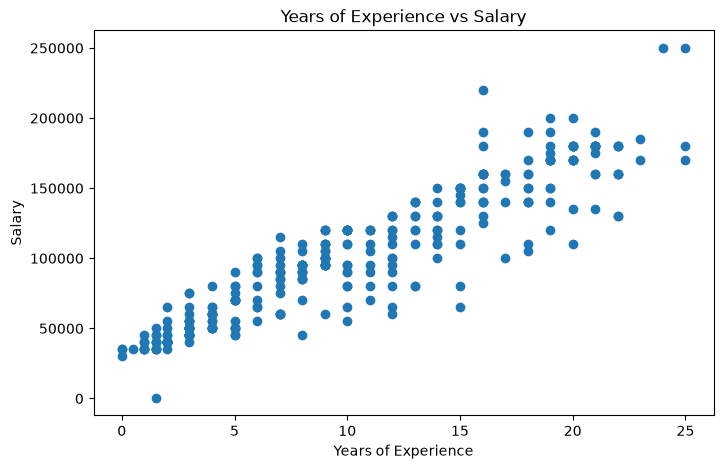

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Years of Experience"],
    df["Salary"]
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Years of Experience vs Salary")

plt.show()

## 8. Define Features and Target

For this project:

- `Salary` is the target variable.
- The remaining employee attributes are potential features.

We will first build a simple model using only Years of Experience.

In [15]:
X_single = df[["Years of Experience"]]
y = df["Salary"]

print("Feature shape:", X_single.shape)
print("Target shape:", y.shape)

Feature shape: (325, 1)
Target shape: (325,)


## 9. Simple Linear Regression

The first model uses only `Years of Experience` to predict `Salary`.

This allows us to measure how well a single feature can predict
an employee's salary.

In [16]:
X_train_single, X_test_single, y_train_single, y_test_single = train_test_split(
    X_single,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train_single))
print("Testing samples:", len(X_test_single))

Training samples: 260
Testing samples: 65


## 10. Train the Simple Linear Regression Model

We use Scikit-learn's LinearRegression algorithm to train the model.

In [17]:
single_model = LinearRegression()

single_model.fit(
    X_train_single,
    y_train_single
)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


## 11. Make Predictions

The trained model is used to predict salaries for the test dataset.

In [18]:
y_pred_single = single_model.predict(X_test_single)

print("Predicted salaries:")
print(y_pred_single)

Predicted salaries:
[ 51638.0040547  133229.33974731 167225.72961923  99232.94987539
 201222.11949115 160426.45164485  51638.0040547   92433.67190101
  78835.11595224  85634.39392662  92433.67190101 133229.33974731
 126430.06177293 126430.06177293  38039.44810593  44838.72608032
 140028.6177217   41439.08709313  51638.0040547   44838.72608032
  31240.17013155 167225.72961923  65236.56000347 126430.06177293
  78835.11595224 160426.45164485  34639.80911874  51638.0040547
 174025.00759362  92433.67190101 160426.45164485  44838.72608032
 174025.00759362  58437.28202909 133229.33974731  78835.11595224
  92433.67190101  99232.94987539  78835.11595224 153627.17367047
  41439.08709313  51638.0040547   99232.94987539 140028.6177217
  44838.72608032  51638.0040547   44838.72608032  44838.72608032
 146827.89569608  78835.11595224  72035.83797786 106032.22784978
  58437.28202909 180824.285568   167225.72961923  65236.56000347
  92433.67190101 153627.17367047  78835.11595224  44838.72608032
 140028

## 12. Evaluate the Simple Linear Regression Model

The model is evaluated using:

### RMSE
Root Mean Squared Error measures the average prediction error.
A lower RMSE indicates better performance.

### R² Score
R² measures how much of the variation in salary is explained
by the model. A higher R² generally indicates better performance.

In [19]:
rmse_single = np.sqrt(
    mean_squared_error(
        y_test_single,
        y_pred_single
    )
)

r2_single = r2_score(
    y_test_single,
    y_pred_single
)

print("Simple Linear Regression Results")
print("---------------------------------")
print(f"RMSE: {rmse_single:.2f}")
print(f"R² Score: {r2_single:.4f}")

Simple Linear Regression Results
---------------------------------
RMSE: 12608.26
R² Score: 0.9304


## 13. Visualize Simple Linear Regression

The scatter plot shows the actual salary values and the regression
line learned from Years of Experience.

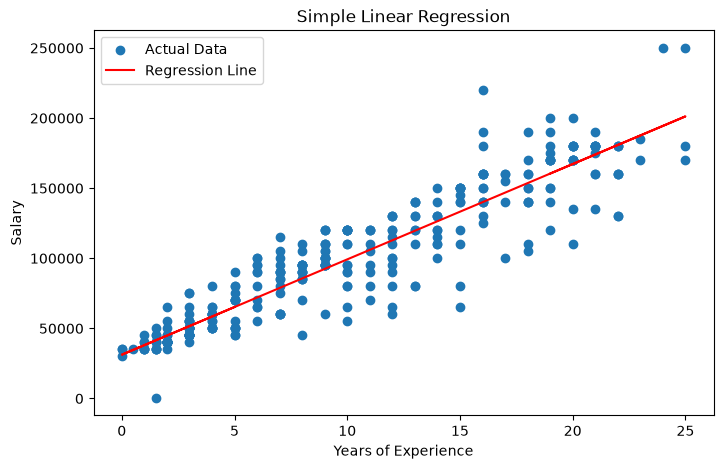

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_single,
    y,
    label="Actual Data"
)

plt.plot(
    X_single,
    single_model.predict(X_single),
    color="red",
    label="Regression Line"
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Simple Linear Regression")
plt.legend()

plt.show()

## 14. Multiple Linear Regression

The second model uses multiple features to predict salary.

### Numerical Features

- Age
- Years of Experience

### Categorical Features

- Gender
- Education Level
- Job Title

Categorical features must be converted into numerical values
before they can be used by the regression model.

In [21]:
X = df.drop("Salary", axis=1)
y = df["Salary"]

categorical_features = [
    "Gender",
    "Education Level",
    "Job Title"
]

numerical_features = [
    "Age",
    "Years of Experience"
]

## 15. Encode Categorical Features

Machine learning algorithms require numerical input.

We use One-Hot Encoding to convert categorical features into
binary numerical columns.

`handle_unknown="ignore"` ensures that unseen categories in the
test data do not cause an error.

In [22]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

## 16. Create the Multiple Linear Regression Pipeline

A Pipeline combines preprocessing and model training into a
single workflow.

The process is:

Categorical Data -->
One-Hot Encoding -->
Numerical Features -->
Linear Regression  -->
Salary Prediction

In [23]:
multiple_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

## 17. Split the Dataset

The dataset is divided into:

- 80% training data
- 20% testing data

The model learns from the training data and is evaluated on
unseen testing data.

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 260
Testing samples: 65


## 18. Train the Multiple Linear Regression Model

In [25]:
multiple_model.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## 19. Make Salary Predictions

The trained Multiple Linear Regression model is used to predict
salaries for the test dataset.

In [26]:
y_pred_multiple = multiple_model.predict(X_test)

print("Predicted salaries:")
print(y_pred_multiple)

Predicted salaries:
[ 45963.34025446 121932.25384377 165411.02351103 118478.71249299
 169403.83199791 170535.12312717  58476.73608181 108546.84229624
  67810.10819536  93225.42579849 108899.63101774 126102.58573971
 121239.86695733 122494.39304894  50968.64780589  57202.40290083
 155671.41425861  47476.18328065  66345.24074948  48476.79535379
  52071.18346727 163325.85756306  74282.47881703 141520.86216044
  69392.92819108 163887.99676823  31946.35582403  47755.88230164
 170262.89850252  99466.59317043 161588.98057765  49878.91270828
 173581.17661276  51734.11261751 156233.55346378  83584.03014653
  71853.98709739  99943.25337671  81556.20960826 138389.27453612
  42109.80550309  67066.0934355  110755.1332075  126489.8009111
  64822.21400669  47252.47754435  66907.37995465  56232.856653
 130957.48550668  90981.54636968  99870.19812581 106876.42785685
  53813.02364357 150097.7873583  142058.38324557  60694.32915713
  81051.07068829 144887.74120065  60687.63793163  61372.73479677
 159841.

## 20. Evaluate the Multiple Linear Regression Model

The model is evaluated using RMSE and R² Score.

A lower RMSE indicates smaller prediction errors, while a higher
R² Score indicates that the model explains more variation in salary.

In [27]:
rmse_multiple = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_multiple
    )
)

r2_multiple = r2_score(
    y_test,
    y_pred_multiple
)

print("Multiple Linear Regression Results")
print("----------------------------------")
print(f"RMSE: {rmse_multiple:.2f}")
print(f"R² Score: {r2_multiple:.4f}")

Multiple Linear Regression Results
----------------------------------
RMSE: 13566.20
R² Score: 0.9194


## 21. Compare Simple and Multiple Linear Regression

We compare both models using RMSE and R² Score.

- Lower RMSE is better.
- Higher R² Score is better.

In [28]:
comparison = pd.DataFrame({
    "Model": [
        "Simple Linear Regression",
        "Multiple Linear Regression"
    ],
    "RMSE": [
        rmse_single,
        rmse_multiple
    ],
    "R² Score": [
        r2_single,
        r2_multiple
    ]
})

comparison

,Model,RMSE,R² Score
0,Simple Linear Regression,12608.261745,0.930365
1,Multiple Linear Regression,13566.204537,0.919381


## 22. Select the Best Model

The model with the lower RMSE will be selected as the best model.

The R² Score is also considered when evaluating model performance.

In [29]:
if rmse_multiple < rmse_single:
    best_model = multiple_model
    best_model_name = "Multiple Linear Regression"
    best_rmse = rmse_multiple
    best_r2 = r2_multiple
else:
    best_model = single_model
    best_model_name = "Simple Linear Regression"
    best_rmse = rmse_single
    best_r2 = r2_single

print("Best Model:", best_model_name)
print(f"RMSE: {best_rmse:.2f}")
print(f"R² Score: {best_r2:.4f}")

Best Model: Simple Linear Regression
RMSE: 12608.26
R² Score: 0.9304


## 23. Save the Best Model

The selected model is saved as a `.pkl` file using Joblib.

The saved model can later be loaded and used for salary predictions
without retraining it.

In [30]:
joblib.dump(
    best_model,
    "best_salary_model.pkl"
)

print("Best model saved successfully!")

Best model saved successfully!


## 24. Predict Salary for a New Employee 1

We can use the trained best regression model to estimate
the salary of a new employee.

In [31]:
# New employee
new_employee_1 = pd.DataFrame({
    "Years of Experience": [4]
})

# Prediction using Best Model
predicted_salary_1 = best_model.predict(new_employee_1)[0]

print(f"Predicted Salary: ${predicted_salary_1:,.2f}")

Predicted Salary: $58,437.28


## Salary Prediction Visualization

The figure below visualizes the Simple Linear Regression model used for salary prediction.

- The **scatter points** represent the actual salaries in the dataset.
- The **red regression line** represents the salaries predicted by the Simple Linear Regression model based on Years of Experience.
- The **star marker** represents the predicted salary for the new employee with **4 years of experience**.
- Since Simple Linear Regression uses only **Years of Experience** as the input feature, the prediction is based on this feature.
- The visualization helps compare the model's predicted salary trend with the actual salary values.

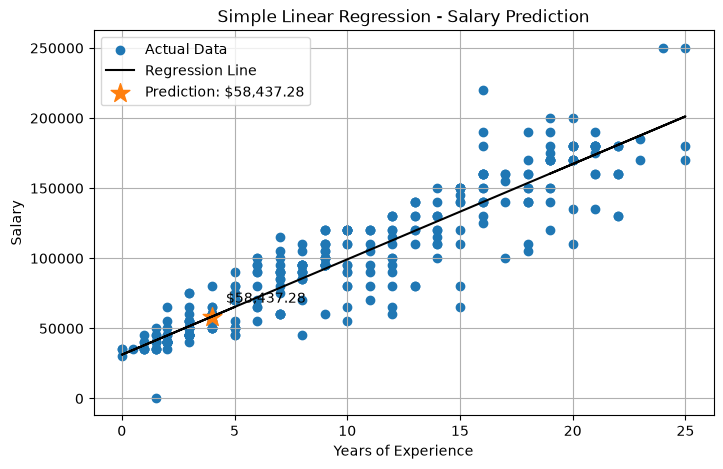

In [32]:
plt.figure(figsize=(8, 5))

# Actual data
plt.scatter(
    X_single["Years of Experience"],
    y,
    label="Actual Data"
)

# Regression line
plt.plot(
    X_single["Years of Experience"],
    single_model.predict(X_single),
    color="black",
    label="Regression Line"
)

# Best model prediction
plt.scatter(
    new_employee_1["Years of Experience"],
    predicted_salary_1,
    s=200,
    marker="*",
    label=f"Prediction: ${predicted_salary_1:,.2f}"
)

# Prediction value
plt.annotate(
    f"${predicted_salary_1:,.2f}",
    (
        new_employee_1["Years of Experience"].iloc[0],
        predicted_salary_1
    ),
    xytext=(10, 10),
    textcoords="offset points"
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Simple Linear Regression - Salary Prediction")
plt.legend()
plt.grid(True)

plt.show()

## 24. Predict Salary for a New Employee 2

We can use the trained Best regression model to estimate
the salary of a new employee.

In [33]:
# New employee 2
new_employee_2 = pd.DataFrame({
    "Years of Experience": [10]
})

# Prediction using Best Model
predicted_salary_2 = best_model.predict(new_employee_2)[0]

print(f"Predicted Salary: ${predicted_salary_2:,.2f}")

Predicted Salary: $99,232.95


## Salary Prediction Visualization

The figure below visualizes the Simple Linear Regression model used for salary prediction.

- The **scatter points** represent the actual salaries in the dataset.
- The **red regression line** represents the salaries predicted by the Simple Linear Regression model based on Years of Experience.
- The **star marker** represents the predicted salary for the new employee with **10 years of experience**.
- Since Simple Linear Regression uses only **Years of Experience** as the input feature, the prediction is based on this feature.
- The visualization helps compare the model's predicted salary trend with the actual salary values.

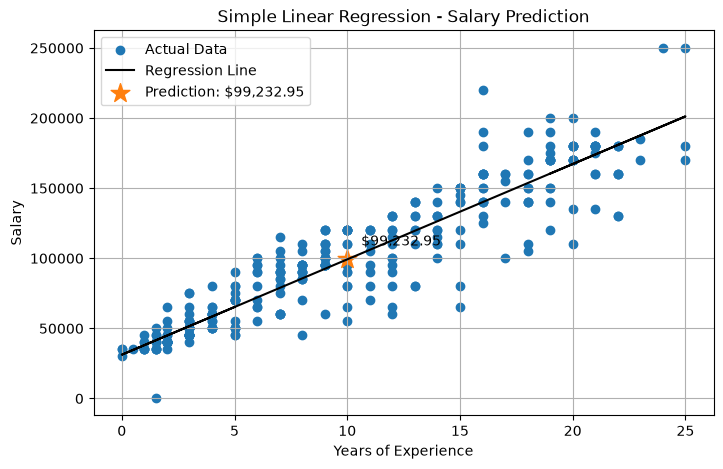

In [34]:
plt.figure(figsize=(8, 5))

# Actual data
plt.scatter(
    X_single["Years of Experience"],
    y,
    label="Actual Data"
)

# Regression line
plt.plot(
    X_single["Years of Experience"],
    single_model.predict(X_single),
    color="black",
    label="Regression Line"
)

# Best model prediction
plt.scatter(
    new_employee_2["Years of Experience"],
    predicted_salary_2,
    s=200,
    marker="*",
    label=f"Prediction: ${predicted_salary_2:,.2f}"
)

# Prediction value
plt.annotate(
    f"${predicted_salary_2:,.2f}",
    (
        new_employee_2["Years of Experience"].iloc[0],
        predicted_salary_2
    ),
    xytext=(10, 10),
    textcoords="offset points"
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Simple Linear Regression - Salary Prediction")
plt.legend()
plt.grid(True)

plt.show()

# Conclusion

In this project, two regression models were developed to predict
employee salary.

### Simple Linear Regression

The model used Years of Experience as the only feature.

### Multiple Linear Regression

The model used multiple numerical and categorical features,
including Age, Gender, Education Level, Job Title, and Years
of Experience.

Both models were evaluated using RMSE and R² Score. The model
with the lower RMSE was selected as the best-performing model
and saved for future predictions.

This project demonstrates data preprocessing, categorical feature
encoding, train/test splitting, regression modeling, evaluation,
model comparison, and model persistence.